# Exploratory Data Analysis — What Is Associated With Employee Performance?

Purpose: answer department-wise performance, and identify which factors are
statistically associated with `PerformanceRating`, ahead of model training

## 1. Imports and Load Processed Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

df = pd.read_csv("../../data/processed/employee_processed.csv")
print(df.shape)
df.head()

(1200, 34)


,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,OverTime,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating,PromotionGapRatio,RoleTenureRatio,ManagerTenureRatio,PriorExperienceYears,AverageTenurePerEmployer,PerformanceLabel
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,4,55,3,2,4,1,No,12,4,10,2,2,10,7,0,8,No,3,0.0000,0.6364,0.7273,0,5.000,Excellent
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,4,42,3,2,1,2,No,12,4,20,2,3,7,7,1,7,No,3,0.1250,0.8750,0.8750,13,6.667,Excellent
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,4,48,2,3,1,5,Yes,21,3,20,2,3,18,13,1,12,No,4,0.0526,0.6842,0.6316,2,3.333,Outstanding
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,2,73,2,5,4,3,No,15,2,23,2,2,21,6,12,6,No,3,0.5455,0.2727,0.2727,2,5.750,Excellent
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,1,84,3,2,1,8,No,14,4,10,1,3,2,2,2,2,No,3,0.6667,0.6667,0.6667,8,1.111,Excellent


## 2. Target Distribution

In [2]:
counts = df["PerformanceRating"].value_counts().sort_index()
percentages = (counts / len(df) * 100).round(1)
pd.DataFrame({"employees": counts, "percent": percentages})

,employees,percent
PerformanceRating,,
2,194,16.2
3,874,72.8
4,132,11.0


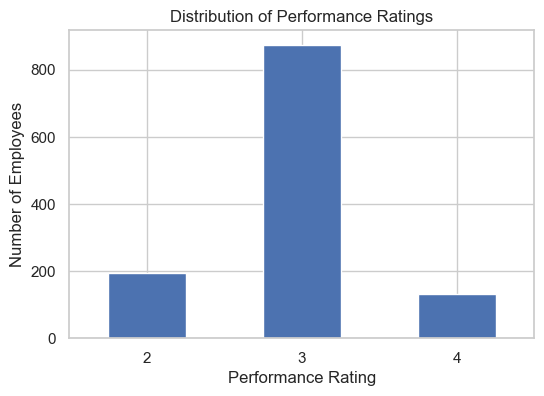

In [3]:
ax = counts.plot(kind="bar", figsize=(6, 4), color="#4C72B0")
ax.set_xlabel("Performance Rating")
ax.set_ylabel("Number of Employees")
ax.set_title("Distribution of Performance Ratings")
plt.xticks(rotation=0)
plt.show()

## 3. Department-Wise Performance

In [4]:
dept_summary = df.groupby("EmpDepartment")["PerformanceRating"].agg(
    headcount="size", mean_rating="mean"
).round(3).sort_values("mean_rating", ascending=False)
dept_summary

,headcount,mean_rating
EmpDepartment,,
Development,361,3.086
Data Science,20,3.050
Human Resources,54,2.926
Research & Development,343,2.921
Sales,373,2.861
Finance,49,2.776


In [5]:
dept_shares = pd.crosstab(df["EmpDepartment"], df["PerformanceRating"], normalize="index").mul(100).round(1)
dept_shares.columns = [f"percent_rating_{c}" for c in dept_shares.columns]
dept_shares.loc[dept_summary.index]   # ordered by mean rating

,percent_rating_2,percent_rating_3,percent_rating_4
EmpDepartment,,,
Development,3.6,84.2,12.2
Data Science,5.0,85.0,10.0
Human Resources,18.5,70.4,11.1
Research & Development,19.8,68.2,12.0
Sales,23.3,67.3,9.4
Finance,30.6,61.2,8.2


In [6]:
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["EmpDepartment"], df["PerformanceRating"]))
print(f"Chi-square = {chi2:.2f}, degrees of freedom = {dof}, p-value = {p:.4f}")

Chi-square = 70.33, degrees of freedom = 10, p-value = 0.0000


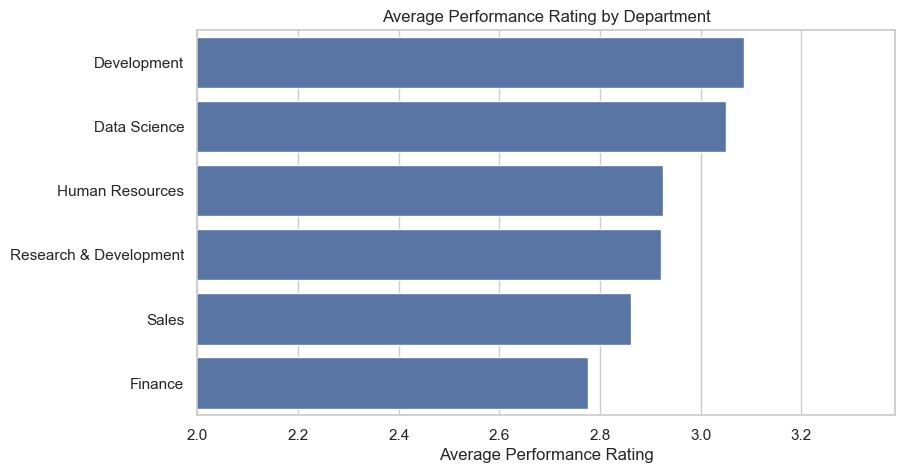

In [7]:
plt.figure(figsize=(9, 5))
order = dept_summary.index
sns.barplot(x=dept_summary["mean_rating"], y=order, order=order, color="#4C72B0")
plt.xlabel("Average Performance Rating")
plt.ylabel("")
plt.title("Average Performance Rating by Department")
plt.xlim(df["PerformanceRating"].min(), dept_summary["mean_rating"].max() + 0.3)
plt.show()

### Observations

- **Department performance is not uniform.** Average rating ranges from **3.09 (Development)**
  down to **2.78 (Finance)** — about a third of a rating point apart.
- Ranking by average rating: **Development > Data Science > Human Resources >
  Research & Development > Sales > Finance**.
- The **share of employees rated 2 (Good, the lowest observed band)** shows the sharpest
  contrast: only **3.6% in Development** vs **30.6% in Finance** — nearly a 9x difference.
- The chi-square test confirms this is **not due to chance**: χ² = 70.33, df = 10,
  **p < 0.0001**. Department is statistically associated with performance rating.
- **Caution on Data Science**: only 20 employees, so its 3.05 average and 5%/85%/10% split
  are based on a small sample and should be treated as less reliable than the larger
  departments (Development n=361, Sales n=373).
- **Business read:** Finance and Sales carry the highest concentration of lower-rated
  employees, and together represent 422 employees (35% of the company) — a meaningful
  share to investigate further with department leaders.

## 4. Which Factors Are Associated With Performance?

Numeric factors are tested with Spearman rank correlation (the rating is ordered:
2 < 3 < 4) and the Kruskal-Wallis test. Categorical factors are tested with the
chi-square test and Cramér's V effect size. Because ~25 factors are tested at once,
p-values are adjusted using the Benjamini-Hochberg false discovery rate correction
to avoid false positives from multiple testing.

In [10]:
#!pip install statsmodels

In [9]:
from statsmodels.stats.multitest import multipletests

target = "PerformanceRating"
exclude = ["EmpNumber", target, "PerformanceLabel", "Attrition"]
factors = [c for c in df.columns if c not in exclude]

numeric_factors = [c for c in factors if pd.api.types.is_numeric_dtype(df[c])]
categorical_factors = [c for c in factors if c not in numeric_factors]

print("Numeric factors:", len(numeric_factors))
print("Categorical factors:", len(categorical_factors))

Numeric factors: 23
Categorical factors: 7


In [11]:
rows = []

for c in numeric_factors:
    rho, _ = stats.spearmanr(df[c], df[target])
    groups = [g[c].values for _, g in df.groupby(target)]
    h, p = stats.kruskal(*groups)
    rows.append({"factor": c, "type": "numeric", "effect_size": abs(rho),
                 "direction": "higher -> better" if rho > 0 else "higher -> worse",
                 "p_value": p})

for c in categorical_factors:
    table = pd.crosstab(df[c], df[target])
    chi2, p, _, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (len(df) * (min(table.shape) - 1)))
    rows.append({"factor": c, "type": "categorical", "effect_size": v,
                 "direction": "-", "p_value": p})

assoc = pd.DataFrame(rows)
assoc["adjusted_p_value"] = multipletests(assoc["p_value"], method="fdr_bh")[1]
assoc["significant"] = assoc["adjusted_p_value"] < 0.05
assoc = assoc.sort_values("effect_size", ascending=False).reset_index(drop=True)
assoc.round(4)

,factor,type,effect_size,direction,p_value,adjusted_p_value,significant
0,EmpEnvironmentSatisfaction,numeric,0.3966,higher -> better,0.0000,0.0000,True
1,EmpLastSalaryHikePercent,numeric,0.2737,higher -> better,0.0000,0.0000,True
2,YearsSinceLastPromotion,numeric,0.2697,higher -> worse,0.0000,0.0000,True
3,PromotionGapRatio,numeric,0.2687,higher -> worse,0.0000,0.0000,True
4,EmpJobRole,categorical,0.2018,-,0.0000,0.0000,True
5,EmpDepartment,categorical,0.1712,-,0.0000,0.0000,True
6,ExperienceYearsInCurrentRole,numeric,0.1661,higher -> worse,0.0000,0.0000,True
7,RoleTenureRatio,numeric,0.1518,higher -> worse,0.0000,0.0000,True
8,YearsWithCurrManager,numeric,0.1350,higher -> worse,0.0000,0.0000,True
9,ExperienceYearsAtThisCompany,numeric,0.1325,higher -> worse,0.0000,0.0000,True


### Observations

**Leading factors (effect size clearly above the rest):**
1. **EmpEnvironmentSatisfaction** (0.397) — by far the strongest single factor. Higher
   satisfaction with the working environment → better rating.
2. **EmpLastSalaryHikePercent** (0.274) — higher salary hikes → better rating.
3. **YearsSinceLastPromotion** (0.270) — longer since last promotion → worse rating.

**Caution — redundancy in the top group.** `PromotionGapRatio` (0.269) is *engineered
directly from* `YearsSinceLastPromotion`, so they are not two independent findings —
they're the same signal measured two ways. Likewise `ExperienceYearsInCurrentRole` (0.166)
and `RoleTenureRatio` (0.152) overlap, as do `YearsWithCurrManager` (0.135) and
`ManagerTenureRatio` (0.118). This needs to be accounted for before finalising the "top 3"
— it should reflect 3 *distinct* underlying drivers, not near-duplicates of the same one.

**Consolidated view of distinct drivers, in order:**
1. **Environment satisfaction** (0.397)
2. **Salary hike percentage** (0.274)
3. **Promotion recency / tenure-in-role cluster** (0.270, 0.269, 0.166, 0.152, 0.135, 0.132,
   0.118, 0.110 combined) — six different measurements of essentially the same
   "career progression stagnation" theme, all pointing the same direction (longer without
   progression → worse rating).

**Department and job role** are also significant (0.202 and 0.171) — consistent with the
department-wise finding in Section 3.

**Not associated with performance** (not significant after adjustment): education background,
marital status, hourly rate, business travel, number of companies worked, distance from
home, age, relationship satisfaction, prior experience, education level, gender, job
involvement, job satisfaction, training times. Notably, **age and gender show no
relationship with rating** — useful to know for the hiring-model fairness discussion later.

## 5. Multicollinearity Check

Since several top factors are suspected to overlap, this checks pairwise correlation
among all numeric factors.

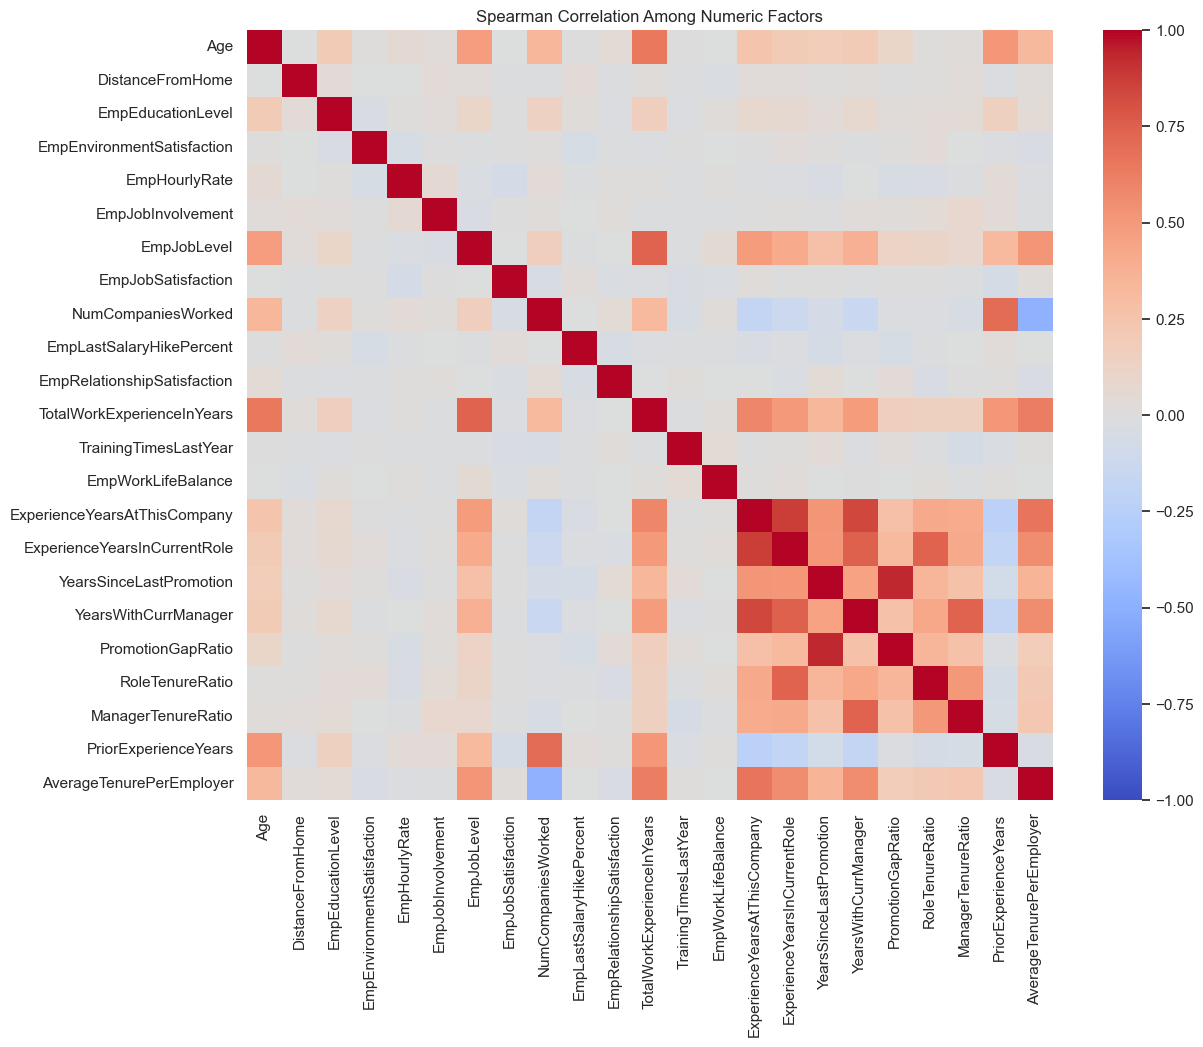

In [12]:
corr = df[numeric_factors].corr(method="spearman")

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman Correlation Among Numeric Factors")
plt.show()

In [13]:
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().rename("correlation").reset_index())
pairs.columns = ["factor_a", "factor_b", "correlation"]
strong_pairs = pairs[pairs["correlation"].abs() >= 0.6].sort_values("correlation", key=abs, ascending=False)
strong_pairs

,factor_a,factor_b,correlation
233,YearsSinceLastPromotion,PromotionGapRatio,0.934262
217,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,0.869786
219,ExperienceYearsAtThisCompany,YearsWithCurrManager,0.840407
226,ExperienceYearsInCurrentRole,YearsWithCurrManager,0.745858
240,YearsWithCurrManager,ManagerTenureRatio,0.740689
121,EmpJobLevel,TotalWorkExperienceInYears,0.738130
228,ExperienceYearsInCurrentRole,RoleTenureRatio,0.734824
160,NumCompaniesWorked,PriorExperienceYears,0.698830
224,ExperienceYearsAtThisCompany,AverageTenurePerEmployer,0.665239
10,Age,TotalWorkExperienceInYears,0.652106


### Observations

The heatmap shows a clear **block of highly correlated tenure variables** in the
bottom-right corner (`ExperienceYearsAtThisCompany`, `ExperienceYearsInCurrentRole`,
`YearsSinceLastPromotion`, `YearsWithCurrManager`, and their ratio versions).

Confirmed by the strong-pairs table:
- **`YearsSinceLastPromotion` and `PromotionGapRatio`: correlation 0.93** — essentially
  the same variable. Expected, since one was engineered from the other.
- **`ExperienceYearsAtThisCompany`** correlates strongly with `ExperienceYearsInCurrentRole`
  (0.87), `YearsWithCurrManager` (0.84), and `AverageTenurePerEmployer` (0.67) — all just
  different angles on "how long this person has been here."
- Everything else (satisfaction scores, salary hike, hourly rate, job involvement,
  relationship satisfaction) is **not** part of this cluster — they vary independently.

**Conclusion — top 3 factors, correctly de-duplicated:**

| Rank | Factor | Effect size | Represents |
|---|---|---|---|
| 1 | **EmpEnvironmentSatisfaction** | 0.397 | Workplace environment satisfaction — independent signal |
| 2 | **EmpLastSalaryHikePercent** | 0.274 | Compensation growth — independent signal |
| 3 | **Career-progression tenure cluster**, best represented by `YearsSinceLastPromotion` | 0.270 | Six correlated columns (`YearsSinceLastPromotion`, `PromotionGapRatio`, `ExperienceYearsInCurrentRole`, `RoleTenureRatio`, `YearsWithCurrManager`, `ExperienceYearsAtThisCompany`, `ManagerTenureRatio`, `AverageTenurePerEmployer`) measuring the same underlying

## 6. Do the Top Factors Explain the Department Differences?

Checks whether Finance and Sales (lower-rated departments) also score lower on the
top 3 factors — which would suggest department differences are downstream of these
drivers, not a separate cause.

In [14]:
df.groupby("EmpDepartment")[
    ["EmpEnvironmentSatisfaction", "EmpLastSalaryHikePercent", "YearsSinceLastPromotion"]
].mean().round(2).sort_values("EmpEnvironmentSatisfaction")

,EmpEnvironmentSatisfaction,EmpLastSalaryHikePercent,YearsSinceLastPromotion
EmpDepartment,,,
Human Resources,2.63,14.74,1.81
Sales,2.65,15.15,2.42
Development,2.71,15.20,2.04
Research & Development,2.78,15.30,2.24
Finance,2.84,15.37,1.96
Data Science,2.95,16.45,1.55


### Observations

**The pattern does NOT cleanly explain the department differences — this is a genuine
finding, not a confirmation.**

Compare to the department ranking by rating from Section 3:
`Development (3.09) > Data Science (3.05) > HR (2.93) > R&D (2.92) > Sales (2.86) > Finance (2.78)`

Against the top-3-factor scores above:
- **Finance has the LOWEST average performance rating (2.78) but is NOT the worst on any
  top factor.** It actually has the 2nd-highest environment satisfaction (2.84), highest
  salary hikes (15.37%), and one of the shortest promotion gaps (1.96 years) — all favourable.
  Yet its employees are rated the worst.
- **Human Resources has the lowest environment satisfaction (2.63) and lowest salary hike
  (14.74%)** — the profile you'd expect for the worst-performing department — yet HR's
  average rating (2.93) is solidly mid-pack, well above Sales and Finance.
- **Data Science scores best on all three factors** (2.95 satisfaction, 16.45% hike, 1.55
  years since promotion) and also has the best-adjacent performance rating (3.05) —
  consistent, but this is the smallest department (n=20), so it's the weakest evidence.

**Conclusion: department performance differences are NOT simply downstream of environment
satisfaction, salary hikes, or promotion timing.** Finance in particular looks like an
outlier — good scores on the known drivers, but still the lowest-rated department. This
points to a **department-specific cause not captured by these three factors** — for example,
work volume, client escalation pressure, management style, or team-specific target-setting
in Finance that isn't visible in this data. Worth flagging as a follow-up question for HR/
Finance leadership rather than something the current dataset can fully explain.

## 7. Secondary Context: Overtime and Attrition

In [15]:
for col in ["OverTime", "Attrition"]:
    print(f"\n{col}:")
    display(df.groupby(col)["PerformanceRating"].agg(headcount="size", mean_rating="mean").round(3))


OverTime:


,headcount,mean_rating
OverTime,,
No,847,2.932
Yes,353,2.989



Attrition:


,headcount,mean_rating
Attrition,,
No,1022,2.957
Yes,178,2.899


### Observations

- **Overtime**: employees who work overtime actually have a very slightly *higher* average
  rating (2.99 vs 2.93) — a small, almost negligible gap. This matches Section 4, where
  `OverTime` was statistically significant but with a small effect size (0.097), far below
  the top 3 factors. Counterintuitive at first glance, but consistent — overtime by itself
  isn't a meaningful driver here.
- **Attrition**: employees who left have a marginally *lower* average rating (2.90) than
  those who stayed (2.96) — a very small gap. This mild pattern is expected (lower
  performers may be more likely to leave, voluntarily or otherwise), and is exactly why
  `Attrition` was excluded as a predictor earlier — it's a downstream consequence of
  performance, not a cause of it.
- Neither factor changes the top-3 conclusion from Section 4.

## 8. Save Outputs

In [16]:
dept_summary.to_csv("../../data/processed/department_performance.csv")
assoc.to_csv("../../data/processed/eda_association_summary.csv", index=False)

print("Saved department_performance.csv and eda_association_summary.csv")

Saved department_performance.csv and eda_association_summary.csv


### Summary of Exploratory Analysis

**Question 1 — Department-wise performance:** confirmed statistically significant
differences (χ² = 70.33, p < 0.0001). Development and Data Science perform best;
Finance and Sales lag, with Finance particularly concerning (30.6% of its employees
rated "Good", the lowest band — nearly 9x Development's rate).

**Question 2 — Top 3 factors (leading toward):**
1. Employee environment satisfaction
2. Last salary hike percentage
3. Career progression / promotion recency (a cluster of correlated tenure measures)

**Key open finding:** these top factors do not explain why Finance underperforms —
Finance scores reasonably well on all three, yet has the lowest rating. This needs
department-specific investigation beyond what this dataset captures.

**Not associated with performance:** age, gender, education, marital status, distance
from home, hourly rate, business travel frequency — useful for the hiring-model fairness
discussion in the next notebook.

Outputs saved for use in `train_model.ipynb` and `visualize.ipynb`:
- `department_performance.csv`
- `eda_association_summary.csv`